# 学习率如何影响模型效果？

用 NumPy 训练一个简单的线性模型：`预测值 = w × x + b`，观察不同学习率的训练过程。

真实数据大致满足 `y = 2x + 1`，并加入少量噪声。所有实验使用相同数据、初始参数和训练次数，只改变学习率。

使用方法：选择安装了 `numpy` 和 `matplotlib` 的 Python 内核，然后从上到下运行所有单元格。修改下面的 `learning_rates` 后，重新运行该单元格及其后面的单元格。


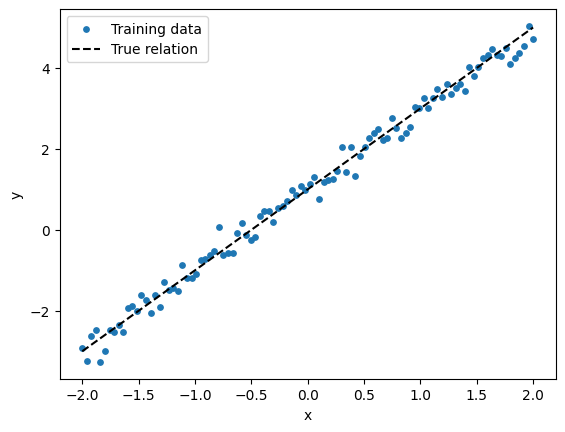

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# 固定随机种子，让每次运行得到同样的数据
rng = np.random.default_rng(42)
x = np.linspace(-2, 2, 100)
y = 2 * x + 1 + rng.normal(0, 0.3, size=x.shape)

plt.scatter(x, y, s=15, label="Training data")
plt.plot(x, 2 * x + 1, "k--", label="True relation")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()


## 调整这里的学习率

- `0.001`：步子很小，在有限训练次数内可能还没学好。
- `0.1`：在本例中通常能较快收敛。
- `0.8`：在本例中步子过大，可能使损失不断增大。

也可以尝试 `[0.01, 0.05, 0.3]`，或增加 `epochs`，观察小学习率在训练更久之后的效果。这些数值仅针对本例；合适的学习率也与数据尺度和模型有关。


In [2]:
# 主要修改这里，然后重新运行后面的单元格
learning_rates = [0.001, 0.1, 0.8]
epochs = 100


In [3]:
def train(learning_rate, epochs):
    """使用均方误差和梯度下降训练；记录初始及每次更新后的损失。"""
    w, b = 0.0, 0.0
    losses = [float(np.mean((w * x + b - y) ** 2))]
    stopped_early = False

    for _ in range(epochs):
        error = w * x + b - y
        dw = 2 * np.mean(error * x)
        db = 2 * np.mean(error)
        next_w = w - learning_rate * dw
        next_b = b - learning_rate * db
        with np.errstate(over="ignore", invalid="ignore"):
            next_loss = float(np.mean((next_w * x + next_b - y) ** 2))

        # 学习率极大时提前停止，避免数值溢出影响图表
        if not np.isfinite(next_loss) or next_loss > 1e12:
            stopped_early = True
            break
        w, b = next_w, next_b
        losses.append(next_loss)

    return {"lr": learning_rate, "w": w, "b": b,
            "losses": np.array(losses), "stopped_early": stopped_early}


assert epochs > 0 and isinstance(epochs, int), "epochs 必须是正整数"
assert len(learning_rates) > 0 and all(np.isfinite(lr) and lr > 0 for lr in learning_rates), "学习率必须是有限正数"
results = [train(lr, epochs) for lr in learning_rates]

for result in results:
    status = "（损失过大，提前停止）" if result["stopped_early"] else ""
    print(f"学习率={result['lr']:g} | 更新次数={len(result['losses']) - 1} | "
          f"w={result['w']:.4f}, b={result['b']:.4f} | "
          f"最终 MSE={result['losses'][-1]:.6f} {status}")


学习率=0.001 | 更新次数=100 | w=0.4694, b=0.1787 | 最终 MSE=3.759331 
学习率=0.1 | 更新次数=100 | w=1.9685, b=0.9849 | 最终 MSE=0.052401 
学习率=0.8 | 更新次数=79 | w=739424.8370, b=0.9849 | 最终 MSE=743722074275.834229 （损失过大，提前停止）


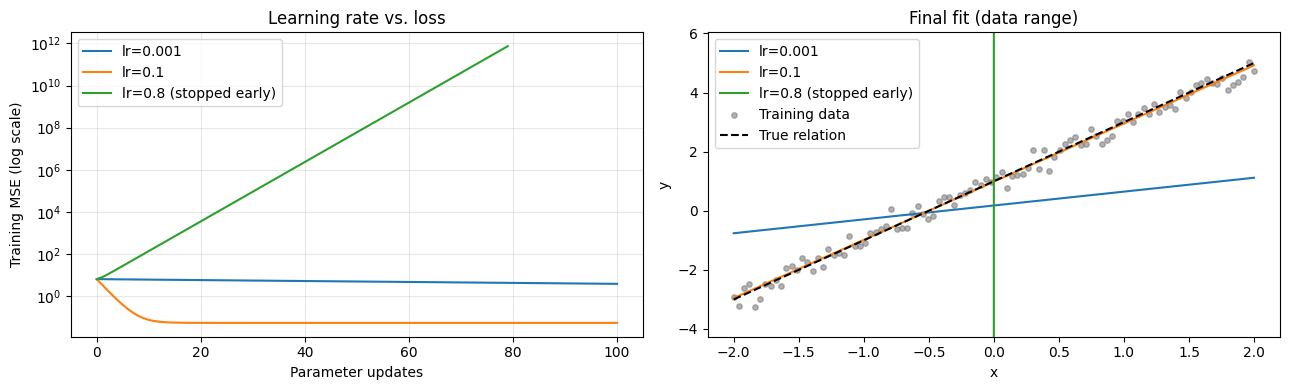

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for result in results:
    label = f"lr={result['lr']:g}"
    if result["stopped_early"]:
        label += " (stopped early)"
    axes[0].plot(result["losses"], label=label)
    axes[1].plot(x, result["w"] * x + result["b"], label=label)

# 对数纵轴便于同时观察收敛和发散
axes[0].set_yscale("log")
axes[0].set_xlabel("Parameter updates")
axes[0].set_ylabel("Training MSE (log scale)")
axes[0].set_title("Learning rate vs. loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].scatter(x, y, s=15, color="gray", alpha=0.6, label="Training data")
axes[1].plot(x, 2 * x + 1, "k--", label="True relation")
# 固定显示数据附近的范围，避免发散的直线压缩其他曲线
axes[1].set_ylim(y.min() - 1, y.max() + 1)
axes[1].set_xlabel("x")
axes[1].set_ylabel("y")
axes[1].set_title("Final fit (data range)")
axes[1].legend()
plt.tight_layout()
plt.show()


## 如何理解结果？

左图表示训练损失：越低说明模型在这批数据上拟合得越好。横轴 0 是尚未训练时的损失。右图展示最终的拟合直线；发散模型的直线可能超出显示范围。

1. 比较 `0.001` 和 `0.1`：同样训练 100 次，哪一个更接近真实直线？
2. 将 `epochs` 改成 `1000`：小学习率是否有改善？
3. 将学习率逐渐调大：损失何时开始振荡或上升？

这里比较的是**训练集拟合效果**，并不等同于模型对新数据的预测能力。由于数据含噪声，正常收敛后的损失也不会等于零。
